wip

### Importing Relevant libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
MASTER_DF_FEATURE_ENGINEERED = '../data/processed/flat_files/MASTER_DF_FEATURE_ENGINEERED.csv'
master_df = pd.read_csv(MASTER_DF_FEATURE_ENGINEERED)

#Working dataframe
df = master_df.copy()
df.head()


,state,fyear,month_num,month_name,generation_mu,capacity_mw,peak_demand_mw,solar_irradiance_kwh_m2_day,temperature_2m_c,days_in_month,...,pr_temp_adjusted,potential_generation_mu,cuf_actual,curtailment_proxy_mu,curtailment_ratio,solar_penetration_ratio,solar-surplus-risk,fy_month_order,gen_roll3_mu,curtailment_roll3_mu
0,Andhra Pradesh,2015-16,4,April,15.44,588.84,6794.0,6.4596,31.19,30,...,0.73143,83.463569,3.641812,68.023569,0.815009,0.086671,-6205.16,1,15.440000,68.023569
1,Andhra Pradesh,2015-16,5,May,13.35,588.84,6732.0,6.4200,34.16,31,...,0.72252,84.672796,3.047271,71.322796,0.842334,0.087469,-6143.16,2,14.395000,69.673183
2,Andhra Pradesh,2015-16,6,June,10.76,588.84,6628.0,4.5766,29.85,30,...,0.73545,59.458598,2.537947,48.698598,0.819034,0.088841,-6039.16,3,13.183333,62.681654
3,Andhra Pradesh,2015-16,7,July,12.03,588.84,6900.0,5.8457,30.87,31,...,0.73239,78.151610,2.745967,66.121610,0.846068,0.085339,-6311.16,4,12.046667,62.047668
4,Andhra Pradesh,2015-16,8,August,12.15,588.84,6500.0,5.1350,29.22,31,...,0.73734,69.114193,2.773359,56.964193,0.824204,0.090591,-5911.16,5,11.646667,57.261467


# Generation trends

Solar Power Generation Over time

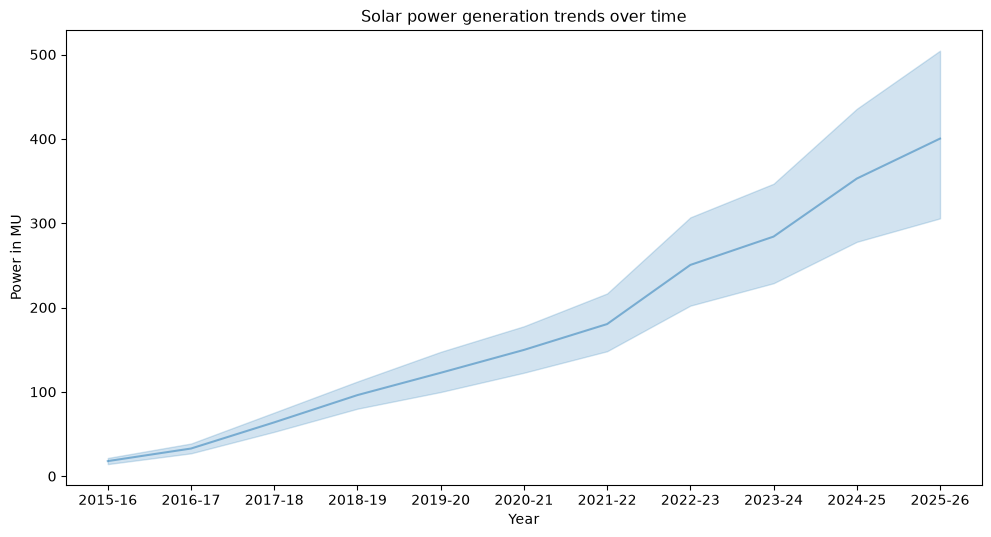

In [3]:
plt.figure(figsize=(12,6))
sns.lineplot(x=df.fyear, y=df.generation_mu, alpha=0.5)
plt.title('Solar power generation trends over time')
plt.xlabel('Year')
plt.ylabel('Power in MU')
plt.show()

Top States with Generation Potential & Actual generation

In [4]:
generation_df = df.groupby('state', as_index=False)[['generation_mu','potential_generation_mu']].mean().sort_values('generation_mu', ascending=False)
generation_df = generation_df.reset_index(drop=True)
generation_df['mean_gap'] = generation_df.potential_generation_mu - generation_df.generation_mu
generation_df = generation_df.rename(columns={
    'generation_mu': 'mean_generation_mu',
    'potential_generation_mu': 'mean_potential_generation_mu',

})
top_gen_df = generation_df.head(10)
top_gen_df


,state,mean_generation_mu,mean_potential_generation_mu,mean_gap
0,Rajasthan,1669.052109,1426.773543,-242.278566
1,Karnataka,824.105504,750.365574,-73.739930
2,Gujarat,648.207054,913.909939,265.702885
3,Tamil Nadu,604.123701,611.435404,7.311703
4,Andhra Pradesh,484.216220,423.668213,-60.548008
5,Telangana,440.602791,411.541975,-29.060816
6,Madhya Pradesh,313.086406,296.806536,-16.279871
7,Maharashtra,297.375891,491.438915,194.063024
8,Uttar Pradesh,195.088750,190.270781,-4.817969
9,Punjab,126.282248,110.663731,-15.618517


## Capacity Trends

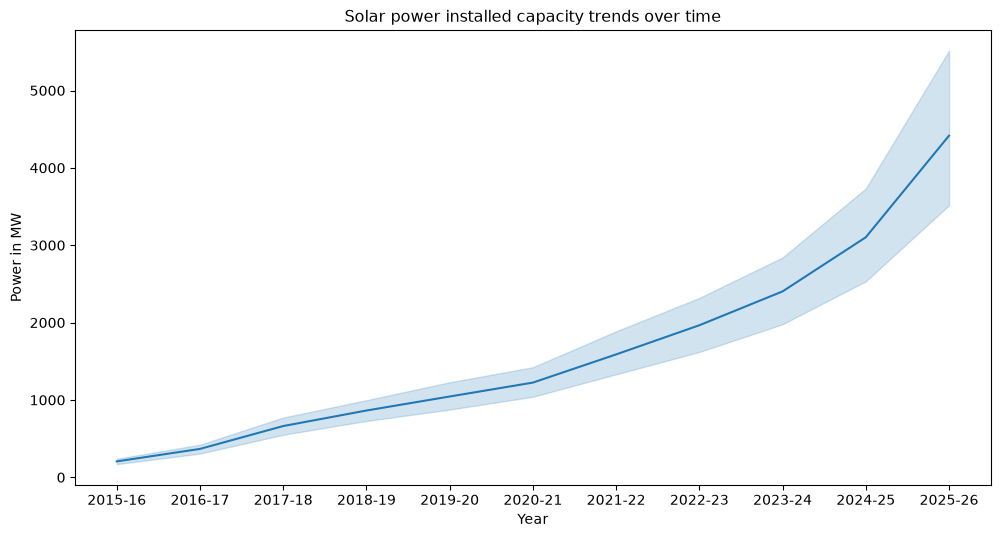

In [5]:
plt.figure(figsize=(12,6))
sns.lineplot(x=df.fyear, y=df.capacity_mw)
plt.title('Solar power installed capacity trends over time')
plt.xlabel('Year')
plt.ylabel('Power in MW')
plt.show()

In [6]:
top_cap_df = df.groupby('state', as_index=False)['capacity_mw'].mean().reset_index(drop=True).sort_values('capacity_mw', ascending=False)
top_cap_df

,state,capacity_mw
26,Rajasthan,12197.411797
9,Gujarat,7853.999070
14,Karnataka,6452.332093
28,Tamil Nadu,5219.606693
18,Maharashtra,4364.495581
0,Andhra Pradesh,3760.076693
29,Telangana,3618.690698
17,Madhya Pradesh,2697.119922
31,Uttar Pradesh,1830.501016
25,Punjab,1041.008837


## Curtailment Trends

Top states curtailing solar generation due to various factors

In [7]:
curtailment_df = df.groupby('state', as_index=False)[['curtailment_proxy_mu', 'curtailment_ratio']].mean().sort_values('curtailment_proxy_mu', ascending=False).reset_index(drop=True)
curtailment_df.head(10)

,state,curtailment_proxy_mu,curtailment_ratio
0,Gujarat,271.295178,0.231858
1,Maharashtra,200.353499,0.242250
2,Karnataka,63.062898,0.163602
3,Rajasthan,56.828155,0.068135
4,Haryana,47.339137,0.579444
5,Tamil Nadu,39.626068,0.126265
6,Chhattisgarh,27.108453,0.431565
7,Uttarakhand,22.260432,0.496657
8,Madhya Pradesh,21.150925,0.051213
9,Andhra Pradesh,20.151946,0.096176


In [8]:
demand_df = df.groupby('state', as_index=False)['peak_demand_mw'].mean().sort_values('peak_demand_mw', ascending=False).reset_index(drop=True)
demand_df.head(10)

,state,peak_demand_mw
0,Maharashtra,23599.248062
1,Uttar Pradesh,20302.976562
2,Gujarat,17795.844961
3,Tamil Nadu,15520.377953
4,Rajasthan,13249.234375
5,Karnataka,12070.821705
6,Madhya Pradesh,11981.148438
7,Telangana,10845.077519
8,Andhra Pradesh,9787.685039
9,Punjab,9763.945736


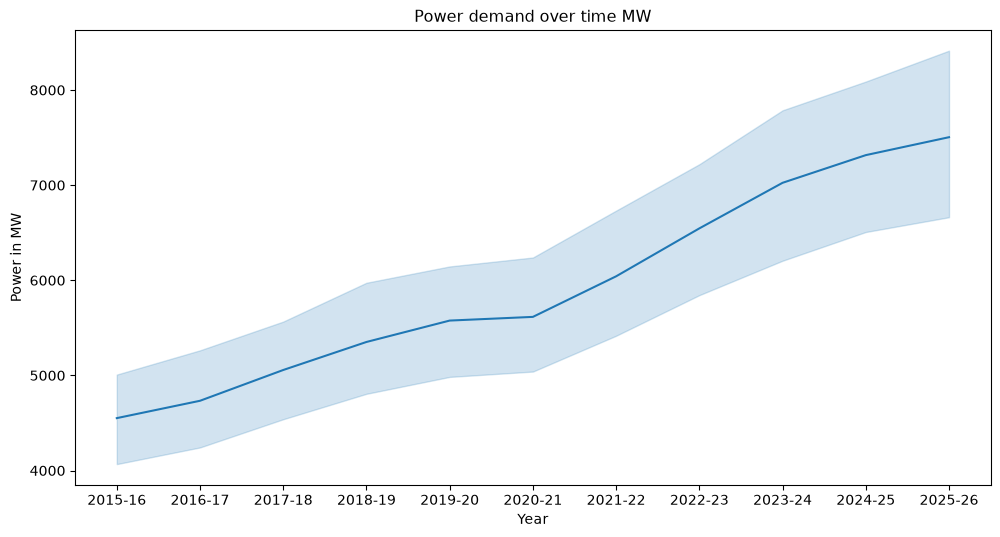

In [10]:
plt.figure(figsize=(12,6))
sns.lineplot(x=df.fyear, y=df.peak_demand_mw)
plt.title('Power demand over time MW')
plt.xlabel('Year')
plt.ylabel('Power in MW')
plt.show()

In [11]:
uttarpradesh = df[df['state']=='Uttar Pradesh']
uttarpradesh

,state,fyear,month_num,month_name,generation_mu,capacity_mw,peak_demand_mw,solar_irradiance_kwh_m2_day,temperature_2m_c,days_in_month,...,pr_temp_adjusted,potential_generation_mu,cuf_actual,curtailment_proxy_mu,curtailment_ratio,solar_penetration_ratio,solar-surplus-risk,fy_month_order,gen_roll3_mu,curtailment_roll3_mu
3968,Uttar Pradesh,2015-16,4,April,6.82,185.09,12967.0,6.1219,28.95,30,...,0.73815,25.091988,5.117630,18.271988,0.728200,0.014274,-12781.91,1,6.820000,18.271988
3969,Uttar Pradesh,2015-16,5,May,8.72,185.09,12991.0,6.9732,35.42,31,...,0.71874,28.757332,6.332287,20.037332,0.696773,0.014248,-12805.91,2,7.770000,19.154660
3970,Uttar Pradesh,2015-16,6,June,6.51,185.09,15391.0,6.2234,36.65,30,...,0.71505,24.709749,4.885011,18.199749,0.736541,0.012026,-15205.91,3,7.350000,18.836356
3971,Uttar Pradesh,2015-16,7,July,6.98,185.09,16438.0,5.4854,30.85,31,...,0.73245,23.053185,5.068734,16.073185,0.697222,0.011260,-16252.91,4,7.403333,18.103422
3972,Uttar Pradesh,2015-16,8,August,10.59,185.09,16872.0,5.2411,30.04,31,...,0.73488,22.099555,7.690243,11.509555,0.520805,0.010970,-16686.91,5,8.026667,15.260830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4091,Uttar Pradesh,2025-26,8,August,375.31,4123.14,30292.0,4.1321,28.65,31,...,0.73905,390.332236,12.234582,15.022236,0.038486,0.136113,-26168.86,5,400.520000,28.688038
4092,Uttar Pradesh,2025-26,9,September,421.21,4123.14,30260.0,4.4498,27.86,30,...,0.74142,408.088282,14.188553,0.000000,0.000000,0.136257,-26136.86,6,397.160000,15.558533
4093,Uttar Pradesh,2025-26,10,October,412.48,4123.14,26269.0,4.0171,23.95,31,...,0.75000,385.091277,13.446272,0.000000,0.000000,0.156958,-22145.86,7,403.000000,5.007412
4094,Uttar Pradesh,2025-26,11,November,423.60,4123.14,19341.0,3.5791,17.70,30,...,0.75000,332.035433,14.269060,0.000000,0.000000,0.213181,-15217.86,8,419.096667,0.000000
